# Assignment: Creating...More Visualizations

Every CSV file sits in the same folder as this notebook and is loaded with a relative path, for example `pd.read_csv('OPD_crimes.csv')`. To run it, unzip the folder and open the notebook from inside it.

Files in the folder:
- `Creating_More_Visualizations.ipynb` (this notebook)
- `OPD_crimes.csv` (Part II, provided with the assignment)
- `ds_salaries.csv` (Part III, provided with the assignment)
- `youtube.csv` (Part IV, provided with the assignment)
- `us_electricity_by_source_2020_2025.csv` (Part V, my own data set)

Note: All dollar amounts in the written answers are spelled out in USD (for example, 150K USD) so the Markdown cells display cleanly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

%matplotlib inline

## Part I: Getting Your Feet Wet With Seaborn

Data source: [Box Office Mojo – Domestic Box Office by Month](https://www.boxofficemojo.com/month/by-year/2023/?grossesOption=calendarGrosses&sort=interval&sortDir=asc), using the calendar grosses option for 2023 and 2024 (viewed October 7, 2026). The values below are taken from the "Cumulative Gross" column, which shows the total domestic gross earned by all films during each month. They are typed in by hand from the table, then converted to millions and rounded to two decimal places in code.

In [2]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

gross_2023 = [584765684, 499510403, 638179407, 900094758, 774058701, 1003756784,
              1362686619, 812895573, 474628398, 556205427, 552082699, 748878132]
gross_2024 = [495884937, 364071918, 749353254, 430213429, 550351927, 965938669,
              1180607445, 892104677, 592408951, 463264478, 900745311, 985666185]

box_office = pd.DataFrame({'Month': months,
                           '2023': gross_2023,
                           '2024': gross_2024})

# Convert to millions and round to two decimal places (e.g. 57,746,920 -> 57.75)
box_office['2023'] = (box_office['2023'] / 1_000_000).round(2)
box_office['2024'] = (box_office['2024'] / 1_000_000).round(2)

# Long format so Seaborn can draw one line per year
box_office_long = box_office.melt(id_vars='Month', var_name='Year',
                                  value_name='Gross (Millions)')
box_office

,Month,2023,2024
0,Jan,584.77,495.88
1,Feb,499.51,364.07
2,Mar,638.18,749.35
3,Apr,900.09,430.21
4,May,774.06,550.35
5,Jun,1003.76,965.94
6,Jul,1362.69,1180.61
7,Aug,812.90,892.10
8,Sep,474.63,592.41
9,Oct,556.21,463.26


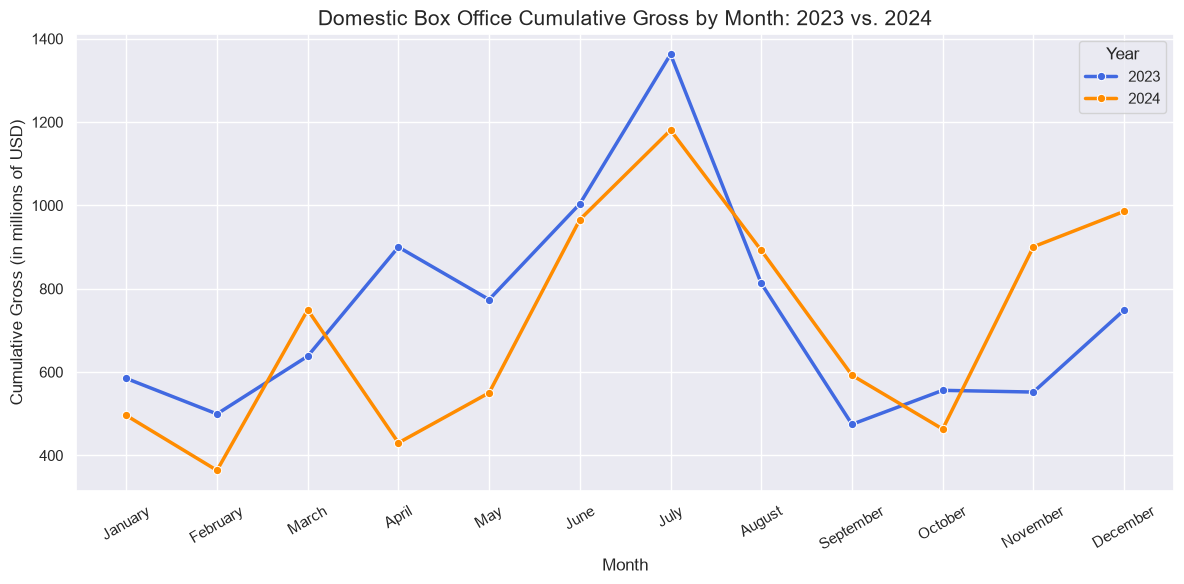

In [3]:
# Dark grid aesthetic and notebook context
sns.set_theme(style='darkgrid', context='notebook')

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=box_office_long, x='Month', y='Gross (Millions)', hue='Year',
             marker='o', linewidth=2.5, palette=['royalblue', 'darkorange'], ax=ax)

ax.set_title('Domestic Box Office Cumulative Gross by Month: 2023 vs. 2024', fontsize=15)
ax.set_xlabel('Month')
ax.set_ylabel('Cumulative Gross (in millions of USD)')
ax.set_xticks(range(12))
ax.set_xticklabels(['January', 'February', 'March', 'April', 'May', 'June', 'July',
                    'August', 'September', 'October', 'November', 'December'], rotation=30)
ax.legend(title='Year')

plt.tight_layout()
plt.show()

In [4]:
print('Three most successful months in 2023:')
print(box_office.nlargest(3, '2023')[['Month', '2023']].to_string(index=False))
print()
print('Three least successful months in 2024:')
print(box_office.nsmallest(3, '2024')[['Month', '2024']].to_string(index=False))
print()
print('2023 total (millions):', round(box_office['2023'].sum(), 2))
print('2024 total (millions):', round(box_office['2024'].sum(), 2))

Three most successful months in 2023:
Month    2023
  Jul 1362.69
  Jun 1003.76
  Apr  900.09

Three least successful months in 2024:
Month   2024
  Feb 364.07
  Apr 430.21
  Oct 463.26

2023 total (millions): 8907.76
2024 total (millions): 8570.6


**What are the three most successful months in 2023?**

1. **July** with 1,362.69 million USD. This was the month of "Barbie" and "Oppenheimer."
2. **June** with 1,003.76 million USD, led by "Spider-Man: Across the Spider-Verse."
3. **April** with 900.09 million USD, led by "The Super Mario Bros. Movie."

**What are the three least successful months in 2024?**

1. **February** with 364.07 million USD
2. **April** with 430.21 million USD
3. **October** with 463.26 million USD

**List at least three factors that may have a significant impact on domestic box office performance.**

- **Release schedule and tentpole films.** One blockbuster can make a month. July 2023 had "Barbie" and "Oppenheimer," and June 2024 had "Inside Out 2." Months without a big franchise release tend to be weak.
- **Seasonality and school calendars.** Summer break (June–August) and the Thanksgiving-to-Christmas holiday season bring in the most moviegoers. Both lines peak in summer and climb again in November and December, while February, September, and October are usually slow.
- **Industry disruptions.** The 2023 writers' and actors' strikes pushed many films out of their planned release dates. That left gaps in the early 2024 calendar, which helps explain why February and April 2024 were much weaker than the same months in 2023.
- **Competition from streaming and home viewing.** Shorter theater-to-streaming windows give some audiences a reason to wait and watch at home.
- **Ticket prices and the economy.** Higher ticket and concession prices, plus inflation, affect how often people go to the movies.

## Part II: Creating a Heatmap

### Loading the data and creating the hour, month, and count fields

`Case Date Time` is stored as text (for example `1/28/2017 12:47`). I convert it to a datetime with `pd.to_datetime()` and then pull out the hour (0–23) and month (1–12) with the `.dt` accessor. I also add a `Count` column with a 1 for every record. Summing it in a pivot table gives the number of crimes in each month/hour combination.

In [5]:
crimes = pd.read_csv('OPD_crimes.csv')   # relative path

crimes['Case Date Time'] = pd.to_datetime(crimes['Case Date Time'], format='%m/%d/%Y %H:%M')
crimes['Hour'] = crimes['Case Date Time'].dt.hour
crimes['Month'] = crimes['Case Date Time'].dt.month
crimes['Count'] = 1

print('Records:', len(crimes))
print('Date range:', crimes['Case Date Time'].min(), 'to', crimes['Case Date Time'].max())
crimes.head()

Records: 181258
Date range: 2017-01-01 00:05:00 to 2024-12-31 21:29:00


,Case Number,Case Date Time,Case Location,Case Offense Location Type,Case Offense Category,Case Offense Charge Type,Case Disposition,Status,Hour,Month,Count
0,2017-00800219,2017-01-28 12:47:00,4100 Block of N ORANGE BLOSSOM TL,Construction Site,Theft,Committed,Closed,Unmapped,12,1,1
1,2017-00800220,2017-01-28 12:54:00,4100 Block of N ORANGE BLOSSOM TL,Industrial/Mfg,Theft,Committed,Closed,Unmapped,12,1,1
2,2017-00800221,2017-01-28 13:02:00,4100 Block of N ORANGE BLOSSOM TL,Industrial/Mfg,Theft,Committed,Closed,Unmapped,13,1,1
3,2017-00178297,2017-04-16 12:50:00,4000 Block of N ORANGE BLOSSOM TL,Bus/Rail Terminal,Robbery,Committed,Closed,Unmapped,12,4,1
4,2017-00193916,2017-04-25 18:41:00,4800 Block of PHEASANT RUN DR,Residence/Single,Assault,Committed,Arrest,Unmapped,18,4,1


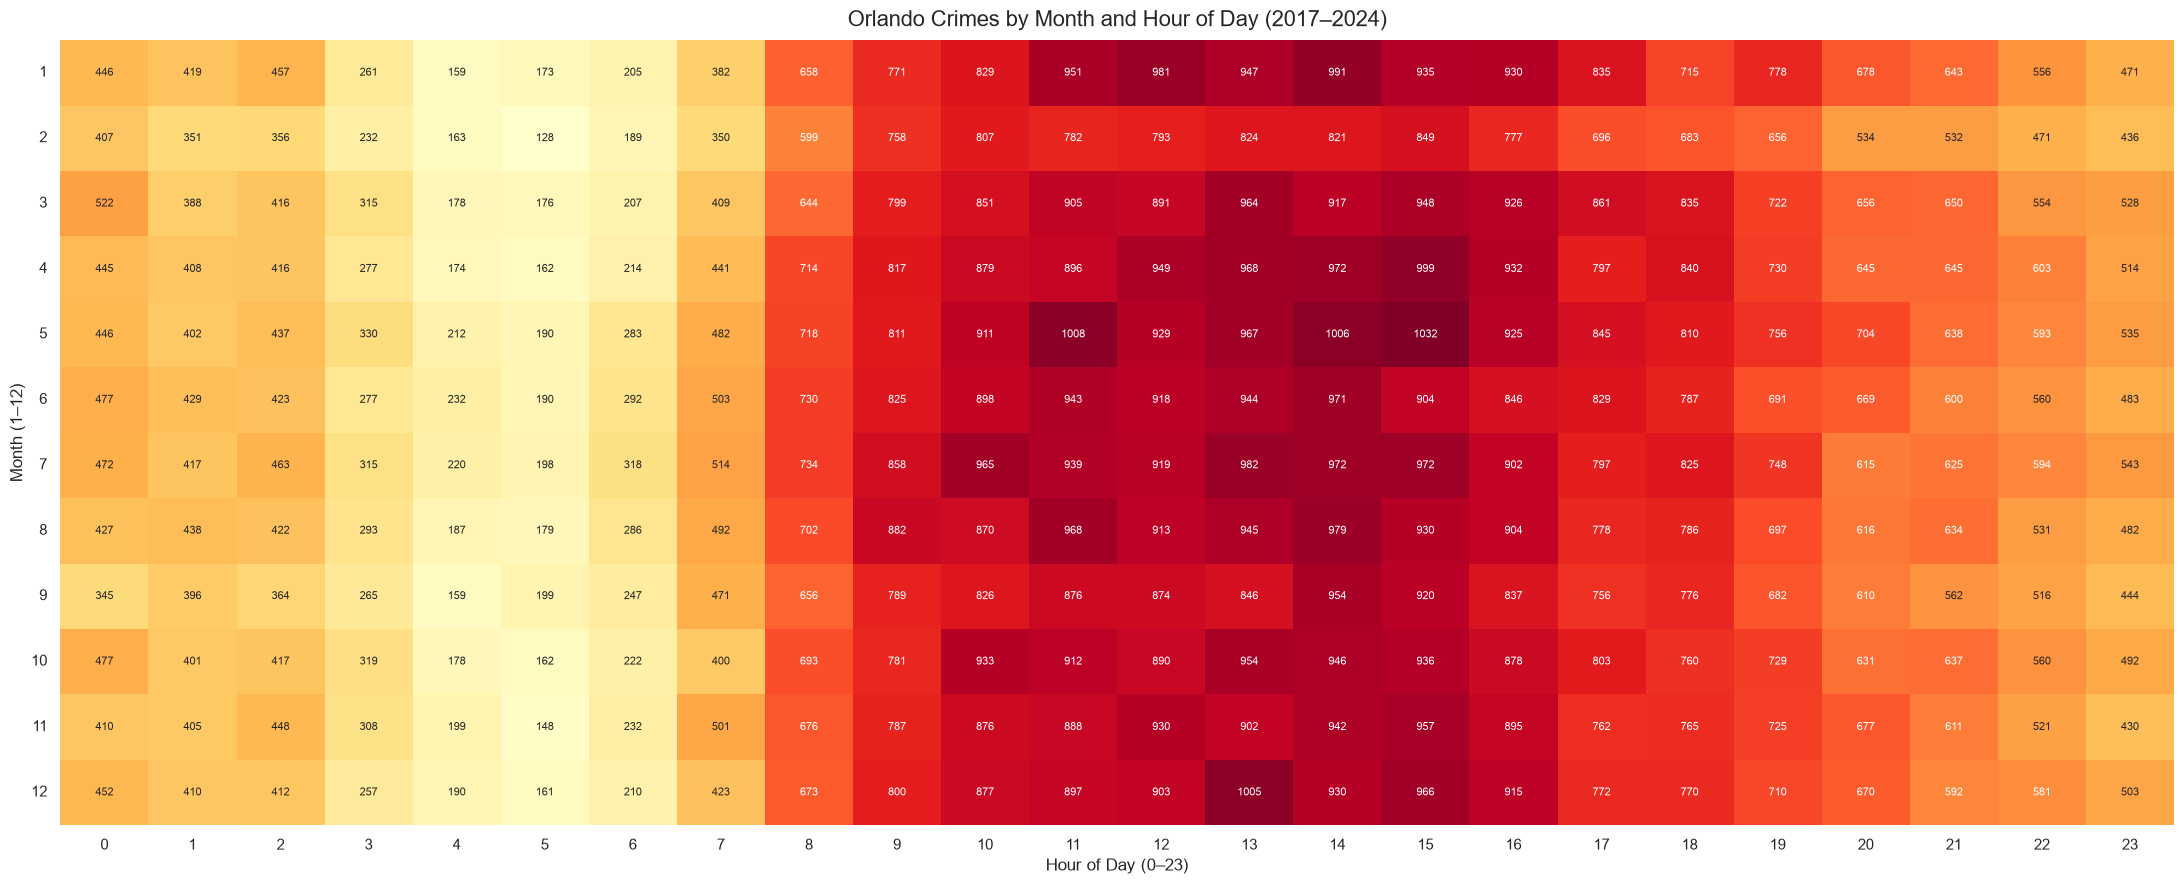

In [6]:
crime_pivot = crimes.pivot_table(index='Month', columns='Hour', values='Count', aggfunc='sum')

sns.set_theme(style='white', context='notebook')
fig, ax = plt.subplots(figsize=(22, 9))
sns.heatmap(crime_pivot, cmap='YlOrRd', annot=True, fmt='d',
            annot_kws={'size': 8}, cbar=False, ax=ax)

ax.set_title('Orlando Crimes by Month and Hour of Day (2017–2024)', fontsize=16, pad=10)
ax.set_xlabel('Hour of Day (0–23)')
ax.set_ylabel('Month (1–12)')
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

In [7]:
hour_totals = crime_pivot.sum(axis=0)
print('Top 5 hours for all crimes:')
print(hour_totals.sort_values(ascending=False).head(5))
print()
print('Quietest hour:', hour_totals.idxmin(), 'with', hour_totals.min(), 'crimes')
print()
print('Most common offense category at 2 PM:')
print(crimes[crimes['Hour'] == 14]['Case Offense Category'].value_counts().head(3))

Top 5 hours for all crimes:
Hour
14    11401
15    11348
13    11248
11    10965
12    10890
dtype: int64

Quietest hour: 5 with 2066 crimes

Most common offense category at 2 PM:
Case Offense Category
Theft       6462
Burglary    1539
Fraud       1210
Name: count, dtype: int64


**According to the heatmap, what would you say is one of the most dangerous hours in Orlando?**

**2 PM (hour 14)** is one of the most dangerous hours. It has the most reported crimes of any hour (11,401 across all eight years), and the cells from about 10 AM to 4 PM are the darkest on the heatmap in every month. Theft is the most common offense at that hour, so this mostly reflects property crime during busy daytime hours. The quietest time is about 4 AM to 5 AM.

### Assault-only heatmap

Assault records: 19833


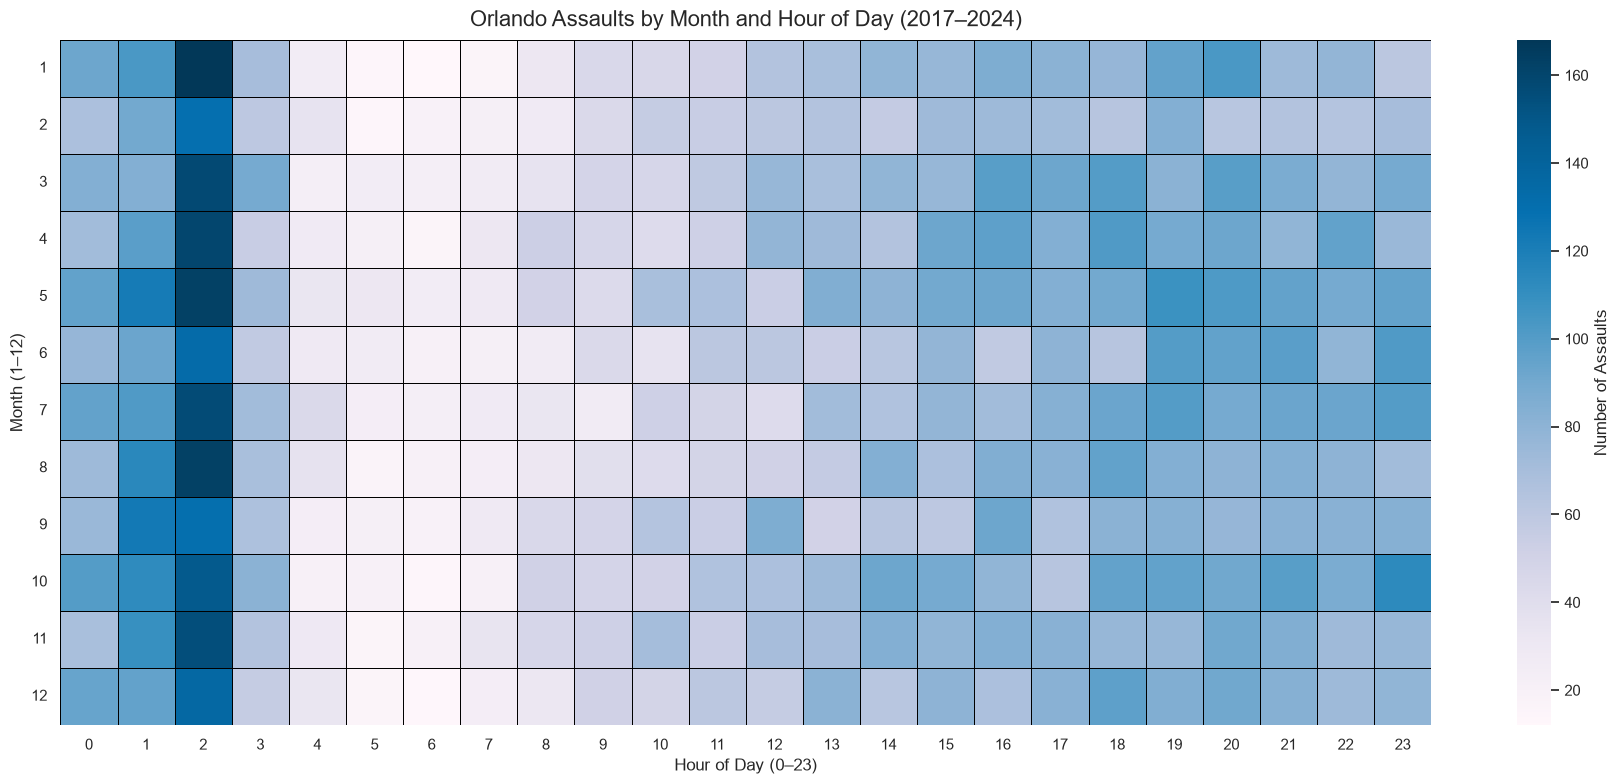

In [8]:
assaults = crimes[crimes['Case Offense Category'] == 'Assault']
print('Assault records:', len(assaults))

assault_pivot = assaults.pivot_table(index='Month', columns='Hour', values='Count', aggfunc='sum')

fig, ax = plt.subplots(figsize=(18, 8))
sns.heatmap(assault_pivot, cmap='PuBu', annot=False, cbar=True,
            linewidths=0.5, linecolor='black',
            cbar_kws={'label': 'Number of Assaults'}, ax=ax)

ax.set_title('Orlando Assaults by Month and Hour of Day (2017–2024)', fontsize=16, pad=10)
ax.set_xlabel('Hour of Day (0–23)')
ax.set_ylabel('Month (1–12)')
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

In [9]:
assault_hours = assault_pivot.sum(axis=0)
print('Top 5 hours for assaults:')
print(assault_hours.sort_values(ascending=False).head(5))
print()
print('Quietest assault hour:', assault_hours.idxmin(), 'with', assault_hours.min(), 'assaults')
print()
print('Crimes by month (all crimes):')
print(crime_pivot.sum(axis=1).sort_values(ascending=False).head(3))
print('Assaults by month:')
print(assault_pivot.sum(axis=1).sort_values(ascending=False).head(3))

Top 5 hours for assaults:
Hour
2     1800
1     1244
19    1081
20    1073
18    1032
dtype: int64

Quietest assault hour: 6 with 227 assaults

Crimes by month (all crimes):
Month
5    15970
7    15907
4    15437
dtype: int64
Assaults by month:
Month
5     1867
10    1780
3     1727
dtype: int64


**What hour would you now say is one of the most dangerous?**

For assaults, **2 AM (hour 2)** is the most dangerous hour, with 1,800 assaults, well ahead of any other hour. The column for hour 2 is clearly darker than the hours around it in almost every month. 2 AM is when bars and nightclubs close in Orlando, which is when large crowds leave at the same time, often after drinking.

**Looking at both heatmaps, what additional conclusions can be drawn?**

- **Different crimes follow different daily patterns.** All crimes combined peak in the middle of the day, which is mostly theft. Assaults build through the evening (about 1,000 per hour from 6 PM to midnight), then spike after midnight and peak at 2 AM. A single "all crimes" heatmap hides that nightlife pattern, so it's worth breaking the data down by category.
- **Early morning is the quietest time for both.** From about 4 AM to 7 AM, both heatmaps show their lightest cells. Total crime bottoms out at 5 AM and assaults at 6 AM.
- **Month matters much less than hour.** The colors change a lot from left to right (hour) but only a little from top to bottom (month). May is the busiest month for both all crimes and assaults, and February is the lowest, mostly because it has fewer days. Orlando's warm weather and year-round tourism likely keep the monthly pattern fairly flat.
- **Planning use.** For police staffing, the daytime hours matter most for property crime, while late-night weekend patrols near entertainment districts would target violent crime.

## Part III: Creating a Bar Graph With Seaborn

The bar heights show the mean salary for each experience level and employment type combination. The black error bars are Seaborn's default 95% confidence intervals for the mean, calculated with bootstrapping. I set `seed=42` so the error bars come out the same every time the notebook runs.

In [10]:
salaries = pd.read_csv('ds_salaries.csv')   # relative path
print(salaries.shape)
print(salaries['experience_level'].value_counts())
print()
print(salaries['employment_type'].value_counts())
salaries.head()

(88584, 9)
experience_level
Senior-level       51596
Mid-level          26748
Entry-level         8381
Executive-level     1859
Name: count, dtype: int64

employment_type
Full-time    88111
Part-time      233
Contract       224
Freelance       16
Name: count, dtype: int64


,work_year,experience_level,employment_type,job_title,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,Entry-level,Part-time,Research Assistant,55000,CA,0,CA,M
1,2025,Entry-level,Part-time,Research Assistant,34700,CA,0,CA,M
2,2025,Entry-level,Part-time,Data Analyst,44000,US,0,US,M
3,2025,Entry-level,Part-time,Data Analyst,38000,US,0,US,M
4,2025,Entry-level,Part-time,Research Assistant,36000,US,0,US,M


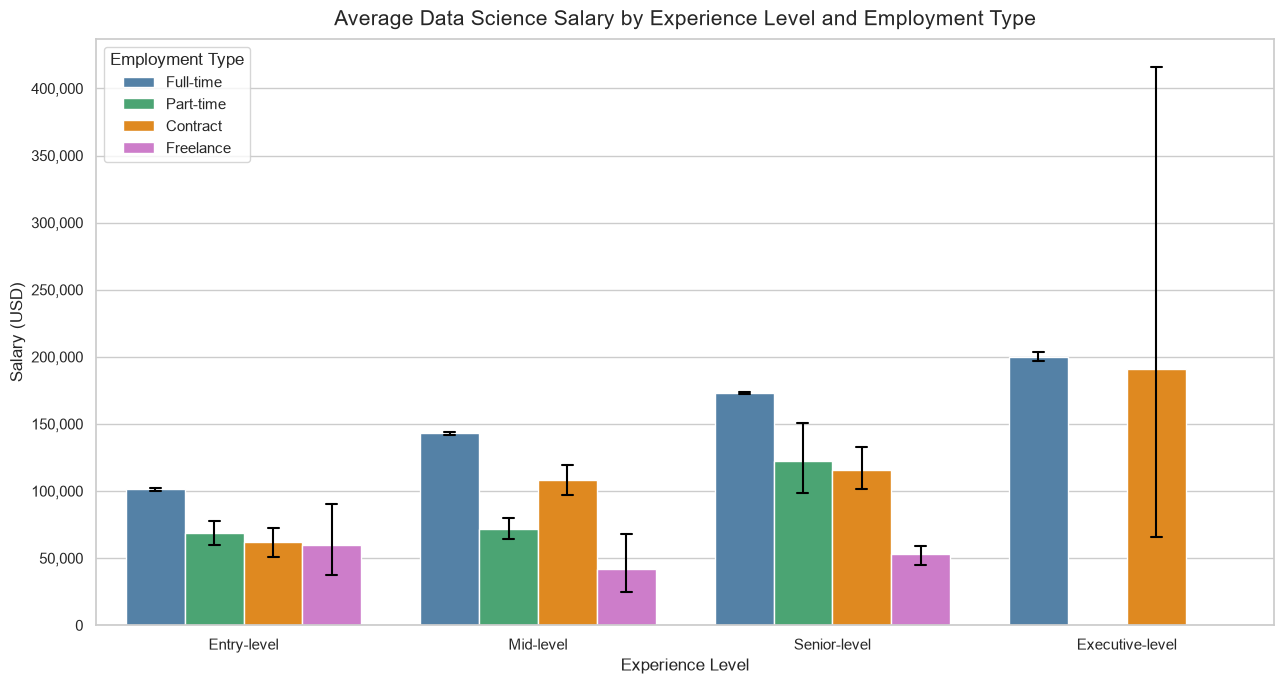

In [11]:
sns.set_theme(style='whitegrid', context='notebook')

experience_order = ['Entry-level', 'Mid-level', 'Senior-level', 'Executive-level']
employment_order = ['Full-time', 'Part-time', 'Contract', 'Freelance']

# Manually chosen colors for the four employment types
employment_colors = {'Full-time': 'steelblue',
                     'Part-time': 'mediumseagreen',
                     'Contract':  'darkorange',
                     'Freelance': 'orchid'}

fig, ax = plt.subplots(figsize=(13, 7))
sns.barplot(data=salaries, x='experience_level', y='salary_in_usd',
            hue='employment_type', order=experience_order, hue_order=employment_order,
            palette=employment_colors, capsize=0.15, seed=42,
            err_kws={'color': 'black', 'linewidth': 1.5}, ax=ax)

ax.set_title('Average Data Science Salary by Experience Level and Employment Type',
             fontsize=15, pad=10)
ax.set_xlabel('Experience Level')
ax.set_ylabel('Salary (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.legend(title='Employment Type', loc='upper left')

plt.tight_layout()
plt.show()

In [12]:
# Supporting numbers for the written answers
summary = (salaries.groupby(['experience_level', 'employment_type'])['salary_in_usd']
                   .agg(['count', 'mean', 'std'])
                   .round(0))
print(summary)
print()
print('Mean salary by experience level:')
print(salaries.groupby('experience_level')['salary_in_usd'].mean().round(0).sort_values())
print()
print('Mean salary by employment type:')
print(salaries.groupby('employment_type')['salary_in_usd'].mean().round(0).sort_values(ascending=False))

                                  count      mean       std
experience_level employment_type                           
Entry-level      Contract            75   61706.0   44917.0
                 Freelance            4   60000.0   29439.0
                 Full-time         8162  101235.0   56197.0
                 Part-time          140   68571.0   52383.0
Executive-level  Contract             3  190619.0  195545.0
                 Full-time         1856  200240.0   76915.0
Mid-level        Contract            77  107893.0   49166.0
                 Freelance            6   42180.0   29897.0
                 Full-time        26601  143004.0   71623.0
                 Part-time           64   71499.0   33714.0
Senior-level     Contract            69  115944.0   68879.0
                 Freelance            6   52891.0    9735.0
                 Full-time        51492  173153.0   70258.0
                 Part-time           29  122075.0   74790.0

Mean salary by experience level:
experi

**In terms of salary, which combination of experience level and employment type has the most uncertainty?**

**Executive-level Contract** has by far the most uncertainty. Its error bar is enormous, running from roughly 65K USD to over 400K USD. Only 3 people are in this group, and their salaries vary a lot (standard deviation of about 196K USD). With so few people and such spread, the true average could be almost anywhere in a very wide range. Executive-level has no Part-time or Freelance workers at all in this data, so those bars don't appear.

**Overall, which experience level earns the lowest salary? Please explain.**

**Entry-level** earns the lowest salary. Its overall mean is about 100K USD, compared with about 143K for Mid-level, 173K for Senior-level, and 200K for Executive-level. In the chart, Entry-level has the shortest Full-time, Part-time, and Contract bars of any experience level. The one exception is Freelance, where Mid-level is lower, but that bar is based on only 6 people. That makes sense, since pay rises with years of experience and responsibility.

**Which employment type seems to be the highest paying? Please explain.**

**Full-time** is the highest paying. It has the tallest blue bar at every experience level, and its overall mean is about 158K USD, compared with about 96K for Contract, 76K for Part-time, and 51K for Freelance. The full-time error bars are also very short, because almost 88,000 of the 88,584 people are full-time employees. That makes this result very reliable. The other employment types have much smaller samples, so their averages are less certain.

## Part IV: Creating Univariate and Bivariate Distributions With Seaborn

In this file, `subscribers millions` is already in millions and `video views billions` is already in billions, so no unit conversion is needed. I just use those units in the axis labels.

In [13]:
youtube = pd.read_csv('youtube.csv', encoding='utf-8-sig')   # relative path
print(youtube.shape)
print(youtube[['subscribers millions', 'video views billions']].describe().round(2))
youtube.head()

(988, 6)
       subscribers millions  video views billions
count                988.00                988.00
mean                  26.34                 13.46
std                   19.15                 16.07
min                   15.00                  0.00
25%                   17.00                  5.42
50%                   21.00                  9.89
75%                   29.00                 16.36
max                  284.00                258.62


,Youtuber,subscribers millions,video views billions,video count,category,started
0,MrBeast,284,52.403,803,Entertainment,2012
1,T-Series,268,258.624,21237,Music,2006
2,Cocomelon - Nursery Rhymes,177,182.881,1188,Education,2006
3,SET India,174,165.395,139720,Shows,2006
4,? Kids Diana Show,123,103.973,1230,People & Blogs,2015


### Histogram with KDE

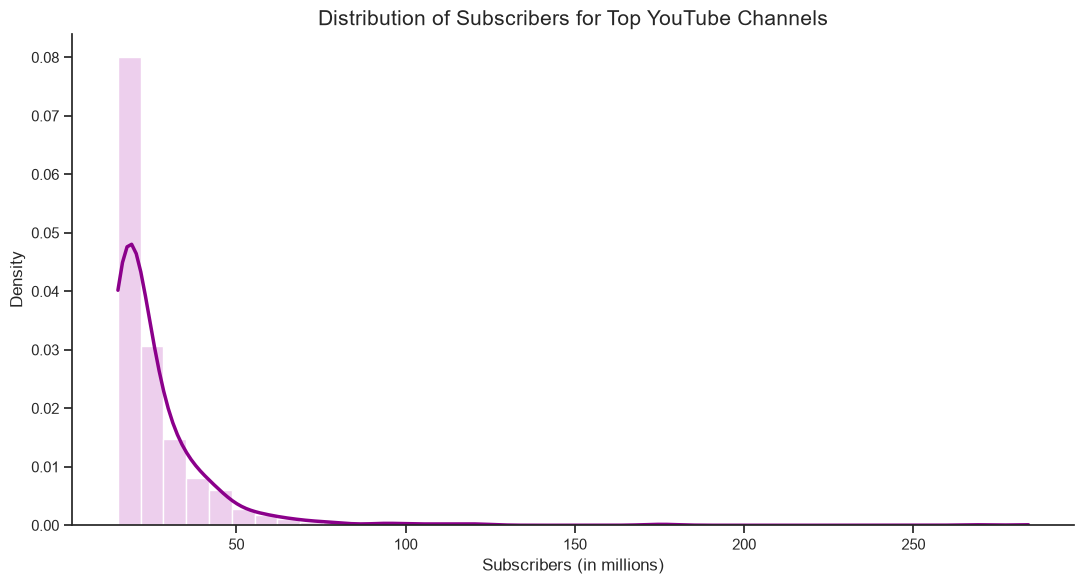

In [14]:
sns.set_theme(style='ticks', context='notebook')

fig, ax = plt.subplots(figsize=(11, 6))
sns.histplot(data=youtube, x='subscribers millions', stat='density', kde=True,
             bins=40, color='plum', edgecolor='white', ax=ax)

# Set the KDE line color to dark magenta
ax.lines[0].set_color('darkmagenta')
ax.lines[0].set_linewidth(2.5)

ax.set_title('Distribution of Subscribers for Top YouTube Channels', fontsize=15)
ax.set_xlabel('Subscribers (in millions)')
ax.set_ylabel('Density')
sns.despine(ax=ax, top=True, right=True)   # remove top and right spines

plt.tight_layout()
plt.show()

### KDE only, with filled area

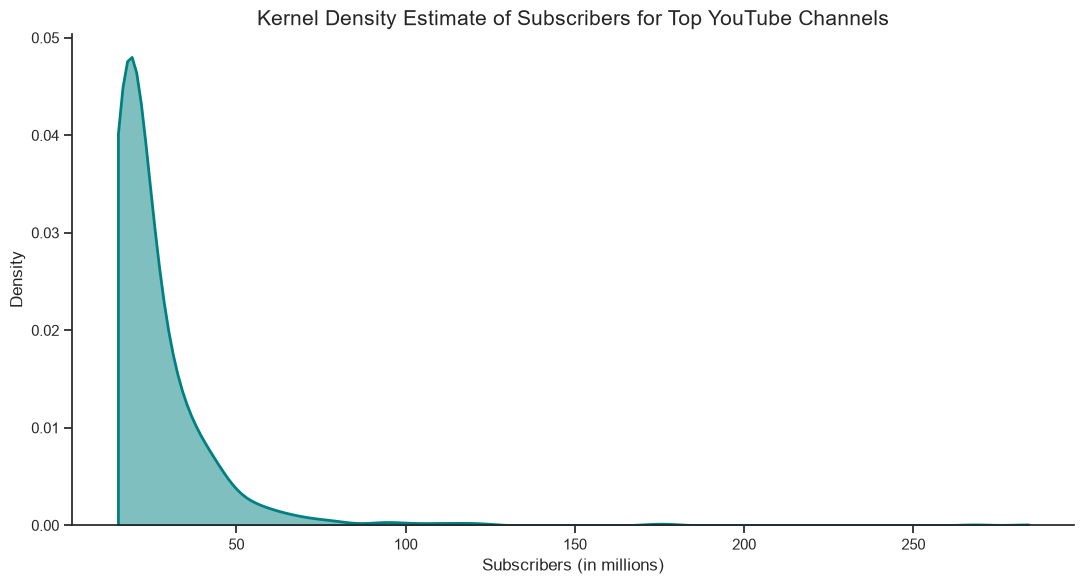

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.kdeplot(data=youtube, x='subscribers millions', fill=True, cut=0,
            color='teal', alpha=0.5, linewidth=2, ax=ax)

ax.set_title('Kernel Density Estimate of Subscribers for Top YouTube Channels', fontsize=15)
ax.set_xlabel('Subscribers (in millions)')
ax.set_ylabel('Density')
sns.despine(ax=ax, top=True, right=True)

plt.tight_layout()
plt.show()

In [16]:
subs = youtube['subscribers millions']
print('Median:', subs.median(), ' Mean:', round(subs.mean(), 2), ' Mode:', subs.mode().tolist())
print('Skewness:', round(subs.skew(), 2))
print('Share of channels with 15-30 million subscribers:', round(((subs >= 15) & (subs <= 30)).mean() * 100, 1), '%')

# Outliers using the 1.5 x IQR rule
q1, q3 = subs.quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
print('Upper outlier fence:', upper_fence, ' Number of outliers:', (subs > upper_fence).sum())
print()
print(youtube.nlargest(5, 'subscribers millions')[['Youtuber', 'subscribers millions', 'video views billions']])

Median: 21.0  Mean: 26.34  Mode: [15]
Skewness: 6.55
Share of channels with 15-30 million subscribers: 76.7 %
Upper outlier fence: 47.0  Number of outliers: 66

                     Youtuber  subscribers millions  video views billions
0                     MrBeast                   284                52.403
1                    T-Series                   268               258.624
2  Cocomelon - Nursery Rhymes                   177               182.881
3                   SET India                   174               165.395
4           ? Kids Diana Show                   123               103.973


**Use the figures to describe this variable's distribution.**

- **Typical value:** A typical channel in this list has about **21 million subscribers** (the median). The peak of the curve is at the low end, near 15–20 million, and 15 million is the most common value. About 77% of the channels have between 15 and 30 million subscribers.
- **Shape:** The distribution is **strongly right-skewed** (skewness of about 6.5). Most of the data is bunched on the left, with a long thin tail stretching to the right. The mean (about 26.3 million) is pulled above the median by the very large channels.
- **Cutoff on the left:** The data starts at exactly 15 million. That's because the data set only includes the most subscribed channels, so the left side of the distribution is cut off rather than tapering naturally.
- **Outliers:** Yes, there are clear outliers. Using the 1.5 × IQR rule, anything above 47 million counts as an outlier. MrBeast (284 million), T-Series (268 million), Cocomelon (177 million), and SET India (174 million) sit far out on the right tail, more than ten times the typical channel.

### Joint plot: subscribers vs. video views

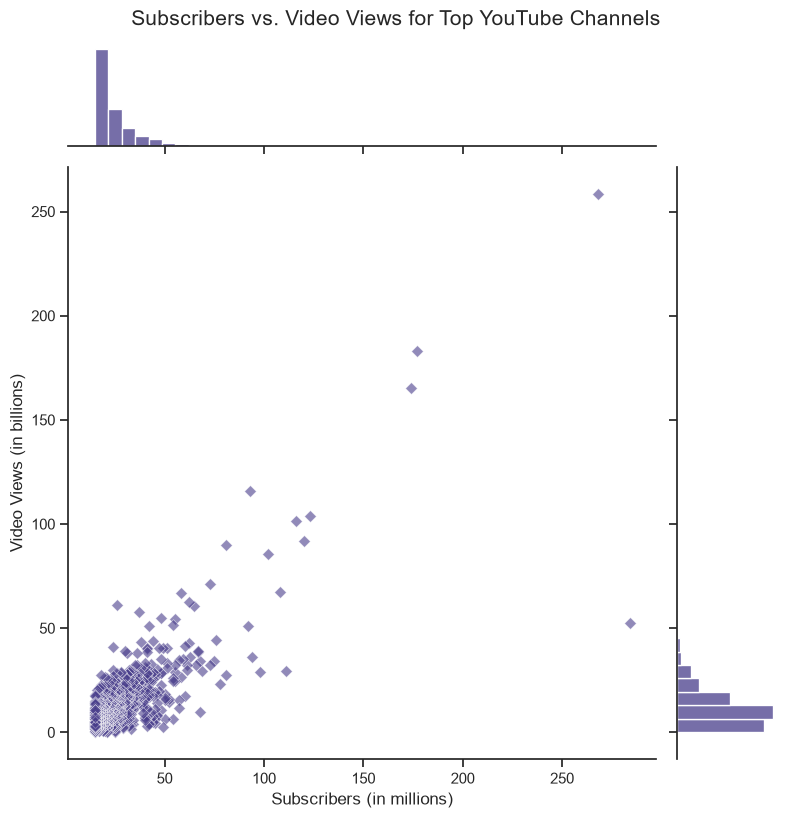

In [17]:
g = sns.jointplot(data=youtube, x='subscribers millions', y='video views billions',
                  kind='scatter', marker='D', color='darkslateblue',
                  height=8, marginal_kws={'bins': 40},
                  joint_kws={'alpha': 0.6, 'edgecolor': 'white'})

g.set_axis_labels('Subscribers (in millions)', 'Video Views (in billions)')
g.figure.suptitle('Subscribers vs. Video Views for Top YouTube Channels', fontsize=15, y=1.02)

plt.show()

In [18]:
print('Correlation between subscribers and views:',
      round(youtube['subscribers millions'].corr(youtube['video views billions']), 2))
print('Median video views (billions):', youtube['video views billions'].median())
print()
print(youtube.nlargest(5, 'video views billions')[['Youtuber', 'subscribers millions', 'video views billions']])

Correlation between subscribers and views: 0.79
Median video views (billions): 9.8935

                      Youtuber  subscribers millions  video views billions
1                     T-Series                   268               258.624
2   Cocomelon - Nursery Rhymes                   177               182.881
3                    SET India                   174               165.395
12                    Sony SAB                    93               115.866
4            ? Kids Diana Show                   123               103.973


**Using this plot, identify a couple takeaways.**

- **More subscribers generally means more views.** The diamonds trend upward from left to right, and the correlation is strong and positive (about 0.79). Channels with bigger audiences usually build up more total views.
- **Most channels are packed into the lower-left corner.** Both marginal histograms are right-skewed, like the subscriber histogram above. Most channels have 15–30 million subscribers and fewer than about 20 billion views (median of about 9.9 billion), so the main cluster is crowded while a few points sit far away.
- **The biggest channels don't all follow the same pattern.** T-Series has the most views by far (about 259 billion with 268 million subscribers), while MrBeast has slightly more subscribers but only about 52 billion views. Music and children's channels such as T-Series, Cocomelon, and SET India get far more views per subscriber, likely because their videos are replayed over and over.
- **Outliers make the plot harder to read.** Because a handful of huge channels stretch both axes, the bulk of the data is squeezed into a small corner. A log scale or a zoomed-in second plot would show the relationship among the typical channels more clearly.

## Part V: Choose Your Own Adventure

### About the data

**File:** `us_electricity_by_source_2020_2025.csv` (included in the zip folder)

**Source:** [Our World in Data – Energy data set](https://github.com/owid/energy-data), downloaded from `owid-energy-data.csv` in their public GitHub repository. Our World in Data compiles electricity generation figures from the Energy Institute's Statistical Review of World Energy and Ember. The full file covers every country and many energy measures, so I narrowed it to United States electricity generation by source for 2020–2025. I also reshaped it into one row per source per year (54 rows).

**Variables:**
| Column | Meaning |
|---|---|
| `country` | Country (United States for every row) |
| `year` | Calendar year (2020–2025) |
| `source` | Electricity source: Natural Gas, Coal, Oil, Nuclear, Wind, Solar, Hydropower, Bioenergy, or Other Renewables (geothermal, wave, and tidal) |
| `category` | Group I assigned to each source: Fossil fuel (coal, gas, oil) or Low-carbon (nuclear and renewables) |
| `generation_twh` | Electricity generated from that source in the year, in terawatt-hours (TWh). One TWh is one billion kilowatt-hours. |

In [19]:
electricity = pd.read_csv('us_electricity_by_source_2020_2025.csv')   # relative path
print(electricity.shape)
electricity.head(9)

(54, 5)


,country,year,source,category,generation_twh
0,United States,2020,Coal,Fossil fuel,773.39
1,United States,2020,Natural Gas,Fossil fuel,1624.17
2,United States,2020,Oil,Fossil fuel,34.34
3,United States,2020,Nuclear,Low-carbon,789.88
4,United States,2020,Wind,Low-carbon,337.94
5,United States,2020,Solar,Low-carbon,130.72
6,United States,2020,Hydropower,Low-carbon,279.95
7,United States,2020,Bioenergy,Low-carbon,54.70
8,United States,2020,Other Renewables,Low-carbon,18.09


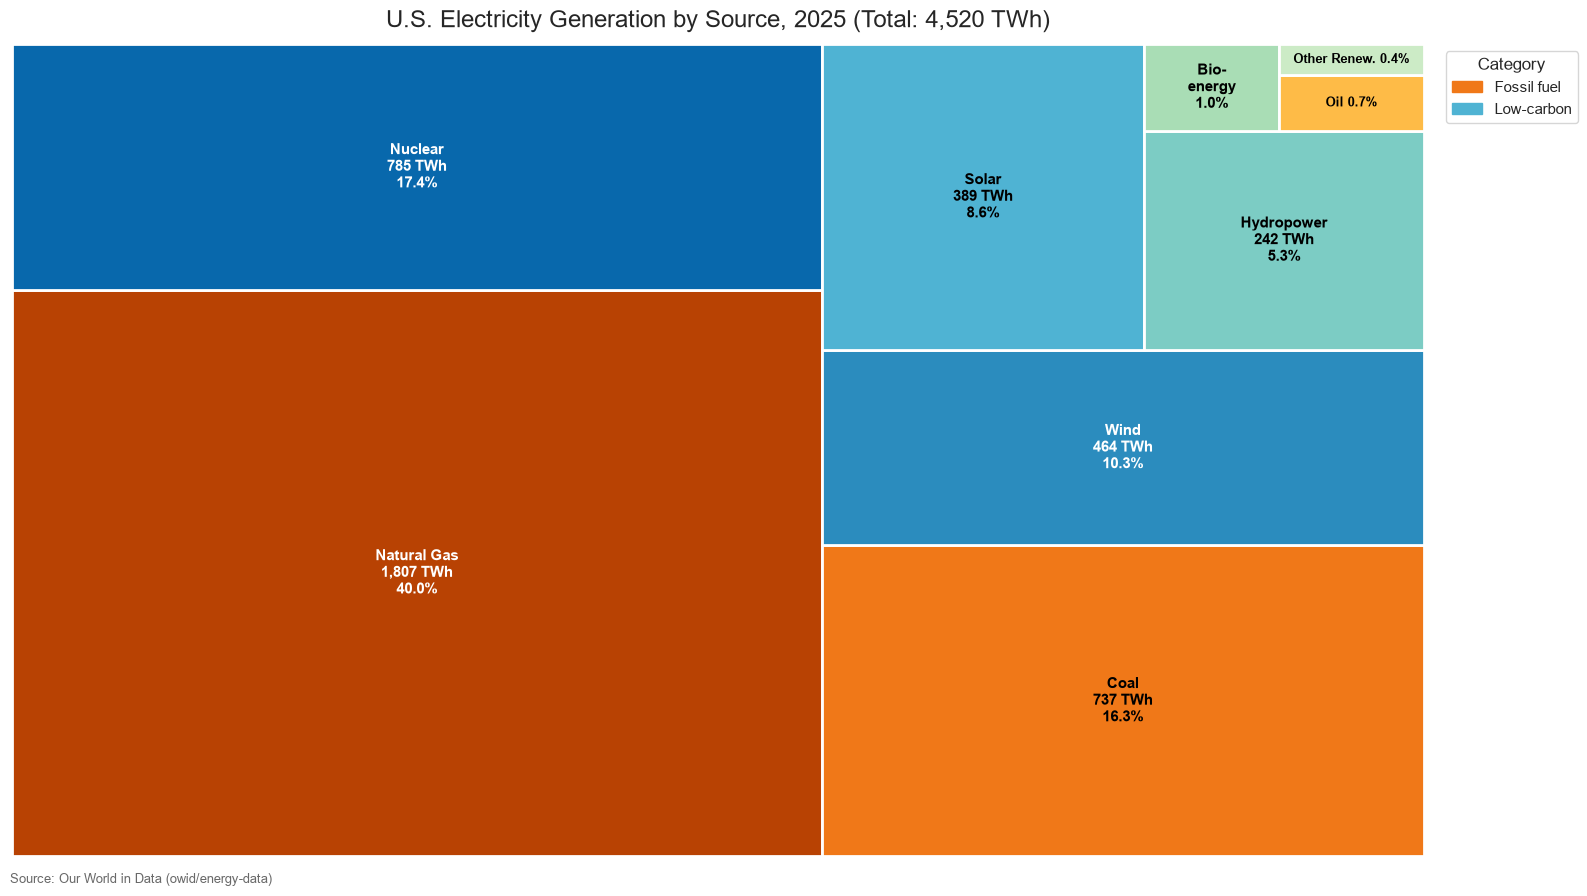

In [20]:
# Use the most recent year and sort largest to smallest for a clean tree map layout
latest_year = electricity['year'].max()
power = (electricity[electricity['year'] == latest_year]
         .sort_values('generation_twh', ascending=False)
         .reset_index(drop=True))
power['share_pct'] = (power['generation_twh'] / power['generation_twh'].sum() * 100).round(1)

# Color palette: warm shades for fossil fuels, cool shades for low-carbon sources
fossil_colors = iter(sns.color_palette('YlOrBr_r', 4))
clean_colors = iter(sns.color_palette('GnBu_r', 7))
colors = [next(fossil_colors) if cat == 'Fossil fuel' else next(clean_colors)
          for cat in power['category']]

# Short names for the smallest rectangles so every label fits
short_names = {'Other Renewables': 'Other\nRenew.', 'Bioenergy': 'Bio-\nenergy'}
labels = []
for s, t, p in zip(power['source'], power['generation_twh'], power['share_pct']):
    if p >= 3:
        labels.append(f"{s}\n{t:,.0f} TWh\n{p}%")      # large rectangles: name, TWh, share
    elif p >= 1:
        labels.append(f"{short_names.get(s, s)}\n{p}%")  # medium rectangles: name and share
    else:
        labels.append(f"{s.replace('Other Renewables', 'Other Renew.')} {p}%")  # thin slivers: one line

fig, ax = plt.subplots(figsize=(16, 9))
squarify.plot(sizes=power['generation_twh'], label=labels, color=colors,
              linewidth=2, edgecolor='white', pad=False,
              text_kwargs={'fontsize': 11, 'fontweight': 'bold', 'color': 'black'}, ax=ax)

ax.set_title(f'U.S. Electricity Generation by Source, {latest_year} '
             f'(Total: {power["generation_twh"].sum():,.0f} TWh)', fontsize=17, pad=12)
ax.axis('off')

# Readable label colors: white text on dark rectangles, black text on light ones,
# and a smaller font for the thin slivers
for text, color, p in zip(ax.texts, colors, power['share_pct']):
    r, g, b = color[:3]
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    text.set_color('white' if luminance < 0.5 else 'black')
    if p < 1:
        text.set_fontsize(9)

# Legend for the two color groups
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=sns.color_palette('YlOrBr_r', 4)[1], label='Fossil fuel'),
                   Patch(color=sns.color_palette('GnBu_r', 7)[2], label='Low-carbon')],
          title='Category', loc='upper left', bbox_to_anchor=(1.01, 1))

fig.text(0.01, 0.01, 'Source: Our World in Data (owid/energy-data)', fontsize=9, color='dimgray')
plt.tight_layout(rect=[0, 0.02, 1, 1])
plt.show()

In [21]:
# Supporting numbers for the analysis
print(power[['source', 'category', 'generation_twh', 'share_pct']].to_string(index=False))
print()
print(power.groupby('category')['share_pct'].sum())
print()
first_year = electricity['year'].min()
compare = electricity.pivot(index='source', columns='year', values='generation_twh')[[first_year, latest_year]]
compare['change_pct'] = ((compare[latest_year] / compare[first_year] - 1) * 100).round(1)
print(compare.sort_values('change_pct', ascending=False))

          source    category  generation_twh  share_pct
     Natural Gas Fossil fuel         1807.34       40.0
         Nuclear  Low-carbon          784.78       17.4
            Coal Fossil fuel          737.15       16.3
            Wind  Low-carbon          464.39       10.3
           Solar  Low-carbon          388.82        8.6
      Hydropower  Low-carbon          241.70        5.3
       Bioenergy  Low-carbon           46.19        1.0
             Oil Fossil fuel           31.72        0.7
Other Renewables  Low-carbon           17.70        0.4

category
Fossil fuel    57.0
Low-carbon     43.0
Name: share_pct, dtype: float64

year                 2020     2025  change_pct
source                                        
Solar              130.72   388.82       197.4
Wind               337.94   464.39        37.4
Natural Gas       1624.17  1807.34        11.3
Nuclear            789.88   784.78        -0.6
Other Renewables    18.09    17.70        -2.2
Coal               773.39   

### Analysis and conclusions

- **Natural gas is the backbone of the U.S. grid.** Natural gas is the biggest rectangle by a wide margin, producing 40% of all U.S. electricity in 2025 (about 1,807 TWh). That's more than nuclear and coal combined.
- **Fossil fuels still supply most electricity, but not overwhelmingly.** The warm-colored rectangles (gas, coal, oil) add up to about 57% of generation, and the cool-colored low-carbon sources make up about 43%. Nuclear (17.4%) is the largest single low-carbon source, slightly ahead of coal (16.3%).
- **Wind and solar are now major sources.** Together, wind (10.3%) and solar (8.6%) produce about 19% of U.S. electricity, more than coal. Solar has grown the fastest: from about 131 TWh in 2020 to about 389 TWh in 2025, nearly triple. Its rectangle would have been much smaller five years earlier.
- **Some sources barely register.** Bioenergy, oil, and other renewables each provide 1% or less. A tree map makes that clear right away, because their rectangles are thin slivers next to the large blocks.
- **Why a tree map works here:** This is a single year's breakdown of a whole into parts. The rectangles show both each source's share and the overall ranking at a glance, and the color grouping adds a second layer (fossil vs. low-carbon) without another chart.